# WuWa Steam Reviews - Data Cleaning & EDA

## Load raw data

In [32]:
import pandas as pd
import json
import os

for base in ["../data", "data"]:
    if os.path.exists(f"{base}/reviews_raw.json"):
        DATA_DIR = base
        break
else:
    raise FileNotFoundError("Cannot find reviews_raw.json - check your working directory")

with open(f"{DATA_DIR}/reviews_raw.json", "r", encoding="utf-8") as f:
    reviews_raw = json.load(f)

with open(f"{DATA_DIR}/patches_raw.json", "r", encoding="utf-8") as f:
    patches_raw = json.load(f)

print(f"Loaded {len(reviews_raw)} reviews and {len(patches_raw)} patch/news items.")

Loaded 28218 reviews and 15 patch/news items.


## Flatten reviews into a DataFrame

`pd.json_normalize` automatically unpacks the nested `author` dict into columns like `author.playtime_forever`.

In [33]:
reviews_df = pd.json_normalize(reviews_raw)
identifying_cols = ['author.steamid', 'author.personaname', 'author.profile_url', 'author.avatar']
reviews_df = reviews_df.drop(columns=identifying_cols)

print(reviews_df.shape)
reviews_df.head()

(28218, 30)


,recommendationid,language,review,timestamp_created,timestamp_updated,voted_up,votes_up,votes_funny,weighted_vote_score,comment_count,...,author.playtime_forever,author.playtime_last_two_weeks,author.playtime_at_review,author.last_played,hardware.system_ram,hardware.os,hardware.cpu_name,hardware.adapter_description,hardware.vram_size,author.deck_playtime_at_review
0,231118029,english,I now have daughter in pgr and wuwa. 10/10,1784811262,1784811262,True,0,0,0.5,0,...,1306,906,1306,1784784521,15636,Windows 11,AMD Ryzen 7 7445HS w/ Radeon 740M Graphics,NVIDIA GeForce RTX 4050 Laptop GPU,5920.0,NaN
1,231114954,english,amazing thats all,1784807797,1784807797,True,0,0,0.5,0,...,1234,1195,1167,1784811534,NaN,NaN,NaN,NaN,NaN,NaN
2,231114402,english,It's peak,1784807138,1784807138,True,0,0,0.5,0,...,19328,1803,19328,1784791901,32559,Windows 11,AMD Ryzen 5 5600G with Radeon Graphics,AMD Radeon RX 6600,8146.0,NaN
3,231111489,english,absolute cinema best anime I've ever played,1784803609,1784803609,True,0,0,0.5,0,...,11507,500,11507,1784644515,NaN,NaN,NaN,NaN,NaN,NaN
4,231108613,english,Best gacha game ever. I'm free to play and it's taken my soul.,1784799766,1784799766,True,1,0,0.5,0,...,18770,2625,18653,1784812054,NaN,NaN,NaN,NaN,NaN,NaN


## Check data types and missing values

In [34]:
print(reviews_df.dtypes)
print()
print(reviews_df.isnull().sum())

recommendationid                      str
language                              str
review                                str
timestamp_created                   int64
timestamp_updated                   int64
voted_up                             bool
votes_up                            int64
votes_funny                         int64
weighted_vote_score                object
comment_count                       int64
steam_purchase                       bool
received_for_free                    bool
refunded                             bool
written_during_early_access          bool
primarily_steam_deck                 bool
app_release_date                      str
reactions                          object
author.persona_status                 str
author.num_games_owned              int64
author.num_reviews                  int64
author.playtime_forever             int64
author.playtime_last_two_weeks      int64
author.playtime_at_review           int64
author.last_played                

In [35]:
missing = reviews_df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

author.deck_playtime_at_review    27359
hardware.vram_size                26310
hardware.os                       26304
hardware.system_ram               26304
hardware.adapter_description      26304
hardware.cpu_name                 26304
dtype: int64

In [36]:
reviews_df['voted_up'].value_counts(normalize=True)

voted_up
True     0.886101
False    0.113899
Name: proportion, dtype: float64

In [37]:
# Drop hardware.* and deck_playtime columns - missing 93%+, not relevant to this task
hardware_cols = [c for c in reviews_df.columns if c.startswith('hardware.')]
reviews_df = reviews_df.drop(columns=hardware_cols + ['author.deck_playtime_at_review'])
print(reviews_df.shape)

(28218, 24)


In [38]:
# Check for duplicates - each review should have a unique recommendationid
print("Duplicate rows by recommendationid:", reviews_df['recommendationid'].duplicated().sum())

Duplicate rows by recommendationid: 0


In [39]:
# weighted_vote_score is showing as object instead of numeric - check why before casting
print(reviews_df['weighted_vote_score'].apply(type).value_counts())
print(reviews_df['weighted_vote_score'].head(10))

weighted_vote_score
<class 'float'>    19038
<class 'str'>       9180
Name: count, dtype: int64
0                     0.5
1                     0.5
2                     0.5
3                     0.5
4                     0.5
5                     0.5
6                     0.5
7    0.476190477609634399
8                     0.5
9                     0.5
Name: weighted_vote_score, dtype: object


In [40]:
# weighted_vote_score comes back as string "0.5" when a review has too few votes
# to compute a real score, and as float otherwise - casting to float unifies both
reviews_df['weighted_vote_score'] = reviews_df['weighted_vote_score'].astype(float)
print(reviews_df['weighted_vote_score'].dtype)
print((reviews_df['weighted_vote_score'] == 0.5).sum(), "reviews still sitting at the default 0.5 (too few votes)")

float64
19172 reviews still sitting at the default 0.5 (too few votes)


In [41]:
# Sanity check: confirm the language filter worked and timestamps fall in a sensible range
print(reviews_df['language'].value_counts())

reviews_df['date_created'] = pd.to_datetime(reviews_df['timestamp_created'], unit='s')
print(reviews_df['date_created'].min(), "to", reviews_df['date_created'].max())

language
english    28218
Name: count, dtype: int64
2025-04-28 20:29:11 to 2026-07-23 12:54:22


In [42]:
# Inspect the 15 patch/news items collected earlier
patches_df = pd.DataFrame(patches_raw)
patches_df['date'] = pd.to_datetime(patches_df['date'], unit='s')
patches_df[['date', 'title']].sort_values('date')

,date,title
14,2025-04-29 10:28:16,"Wuthering Waves arrives on Steam, another with anti-cheat problems on Steam Deck and Desktop Linux"
13,2025-06-11 20:00:54,"New Content in Wuthering Waves Version 2.4 ""Lightly We Toss the Crown"""
12,2025-07-15 15:15:31,"Wuthering Waves now Steam Deck Playable, and works on Desktop Linux with one tweak"
11,2025-07-23 20:00:37,New Content in Wuthering Waves Version 2.5: Unfading Melody of Life
10,2025-08-27 20:00:13,"New Content in Wuthering Waves V2.6: By Sun's Scourge, By Moon's Revelation"
9,2025-10-08 20:00:33,New Content in Wuthering Waves Version 2.7: Dawn Breaks on Dark Tides
8,2025-10-10 02:00:02,New Content in Wuthering Waves Version 2.7: Dawn Breaks on Dark Tides
7,2025-11-19 20:00:56,New Content in Wuthering Waves Version 2.8: To the City Set in Amber
6,2025-12-21 09:00:00,Wuthering Waves 3.0 Hands-On: Exploring Lahai-Roi and the Game’s New Motorbike System
5,2025-12-24 20:00:19,New Content in Wuthering Waves Version 3.0: We Who See the Stars


In [43]:
# Drop preview/hands-on articles - these aren't actual patch releases
patches_df = patches_df[~patches_df['title'].str.contains('Hands-On', case=False)]
print(len(patches_df), "actual patch/milestone entries remaining")

14 actual patch/milestone entries remaining


In [44]:
import matplotlib.pyplot as plt

# Weekly % positive and review counts, used by the sentiment-over-time chart below
reviews_df['week'] = reviews_df['date_created'].dt.to_period('W').dt.start_time
weekly_positive = reviews_df.groupby('week')['voted_up'].mean()
weekly_count = reviews_df.groupby('week').size()

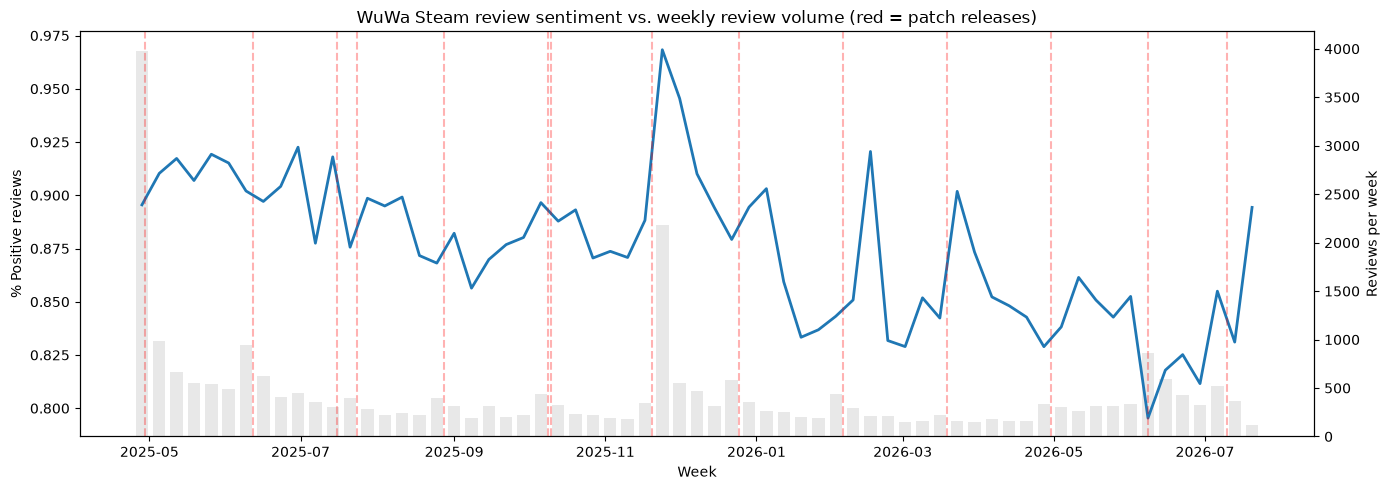

In [45]:
# Overlay weekly review volume, since a % positive from very few reviews
# is far noisier than one computed from hundreds
fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

ax2.bar(weekly_count.index, weekly_count.values, width=5, color='lightgray', alpha=0.5, label='Review count')
ax2.set_ylabel('Reviews per week')

ax1.plot(weekly_positive.index, weekly_positive.values, color='tab:blue', linewidth=2, label='% Positive')
ax1.set_ylabel('% Positive reviews')
ax1.set_xlabel('Week')
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

for d in patches_df['date']:
    ax1.axvline(d, color='red', alpha=0.3, linestyle='--')

plt.title('WuWa Steam review sentiment vs. weekly review volume (red = patch releases)')
fig.tight_layout()
plt.show()

In [46]:
# Find the exact week with the lowest % positive around mid-2026
lowest_week = weekly_positive.idxmin()
print("Lowest %positive week:", lowest_week)
print("Review count that week:", weekly_count[lowest_week])
print("%positive that week:", weekly_positive[lowest_week])

Lowest %positive week: 2026-06-08 00:00:00
Review count that week: 865
%positive that week: 0.7953757225433526


## Investigating the sentiment dip (week of 2026-06-08)

In [47]:
# Read the actual reviews written during that week to judge if this is
# a real signal or just noise from a tiny sample
dip_reviews = reviews_df[reviews_df['week'] == lowest_week][['voted_up', 'review', 'author.playtime_forever']]
dip_reviews

,voted_up,review,author.playtime_forever
2365,False,"probs just my pc but\nfor me it runs horible, (i can run cyberpunk and rdr2 at around 45 fps) \ncan bearly load in, and it took me litiraly nearly a hour just to download the exes stuff and i did ...",86
2366,True,greatest game of all time. SOLOS EVERYTHING,7473
2367,True,"The game has great combat and an interesting story. I don't like the unbelievably long dialog, as most of it should have just been a cutscene rather than dialog that you have to click through. The...",972
2368,True,"Despite the ridiculous monetization practices (to be expected as it's a Gacha Game), the absolute mess that is the early game, the massive volume of stability issue for players with NVIDIA GPUs (i...",1481
2369,True,Dropped the game a couple years back cuz my wallet was crying from playing 3 gacha games at the same time and now I'm back. Seen alot of vids and reels all over the place and got curious about the...,14533
...,...,...,...
3225,True,I very much enjoy this game. It has pretty graphics... I'll be honest I just like jingling keys in front of my face.,7634
3226,True,''I once dreamt that we were dear to each other.''\n''i woke up to find we were strangers.''\n,6977
3227,True,goat gatcha open world game,45902
3228,True,"awsome game, big open world",4585


In [48]:
# 865 is not a small sample - the earlier "noise" hypothesis is wrong, this dip is real.
# Isolate the negative reviews from that week to find the common complaint.
dip_negative = reviews_df[(reviews_df['week'] == lowest_week) & (~reviews_df['voted_up'])]
print(f"{len(dip_negative)} negative reviews out of {weekly_count[lowest_week]} total that week")

pd.set_option('display.max_colwidth', 200)
dip_negative[['review', 'author.playtime_forever']].head(15)

177 negative reviews out of 865 total that week


,review,author.playtime_forever
2365,"probs just my pc but\nfor me it runs horible, (i can run cyberpunk and rdr2 at around 45 fps) \ncan bearly load in, and it took me litiraly nearly a hour just to download the exes stuff and i did ...",86
2370,"Wuthering Waves is just another gacha open world out of the bunch, it doesn't do anything unique whilst it's competitors at least try to (Arknights: Endfield at least tried to add automation into ...",223
2372,"Game doesnt want to use my Steam account to create a login, so I am forced to create an account outside of it.",596
2377,The fact that it drags the cursor multiple times (at least three times in my experience) upon startup and steals the window's focus is unbearably annoying when you boot it every day. It's a comple...,28598
2381,Games not as bad as genshin but still garbage~ Also it would be less annoying if I didn't need to click on every single trash offer just to get rid of the ♥♥♥♥ red marker thats always on my screen...,15259
2384,Whoever decided the download had to take over 1 day to download and accompany that download with background music you can't control really sucks.,764
2385,game nhu cac roll lech,167
2388,"Game is pretty but that's about it. Maybe there is something great hidden but spending all this time downloading and then being greeted with at the least 2 hours of exposition, uninteresting dialo...",227
2392,"Strange game, gave it a try but so much nonsense imo",146
2395,"Get a discord quest to try Wuthering Waves. Cool enough I guess and only wants 15 minutes. Sure why not I think.\n\n100GB of download for what looks like a phone game. Rough, but fine, it's happen...",59


In [49]:
# Quantify the "new-player churn via Discord Quest" hypothesis instead of eyeballing it
print("Median playtime (forever) - dip week:", dip_reviews['author.playtime_forever'].median())
print("Median playtime (forever) - overall dataset:", reviews_df['author.playtime_forever'].median())

keywords = ['download', 'discord', 'login', 'account', 'install']
mentions = dip_negative['review'].str.contains('|'.join(keywords), case=False, na=False)
print(f"{mentions.sum()} / {len(dip_negative)} negative reviews that week mention onboarding-related keywords")

Median playtime (forever) - dip week: 3929.0
Median playtime (forever) - overall dataset: 8386.5
31 / 177 negative reviews that week mention onboarding-related keywords


## EDA Summary

Sentiment shows a gradual decline rather than a single review-bomb event, dropping
from ~90% positive at launch to a noisier 80-85% band by mid-2026, with short-lived
spikes around major content updates (most notably Version 3.0). The lowest point in
the timeline (week of 2026-06-08) was initially suspected to be a low-sample noise
artifact, but with 865 reviews that week this turned out to be a real signal.
Investigating the negative reviews from that week revealed a mixed cause: median
playtime among reviewers that week (3,929 hours) was less than half the dataset-wide
median (8,386.5), and roughly 17.5% of negative reviews mentioned onboarding friction
(large download size, forced external account creation, a Discord Quest campaign
driving new low-intent installs). However, this is a contributing factor rather than
the dominant one - the remaining ~82.5% of negative reviews raised recurring,
non-specific complaints (monetization, gacha fatigue) that appear consistently across
most weeks in the dataset, not just this one.